# City, suburb and village

The same rules produce very different grids in different places. This notebook compares the three example areas, an
urban, a semi-urban and a rural one, and then the grids of all of Bavaria by settlement type.

**Needs:** the `notebooks` extra (`uv sync --extra notebooks`). With a database in your `.env` the notebook reads the grids from it, otherwise from the example data that ship with pylovo (`data/examples`: three Bavarian postcode areas).

In [1]:
areas = [80805, 85256, 85307]    # urban, semi-urban, rural
version_id = None                # None: the version of your configuration, or of the example data

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from pylovo.examples import EXAMPLE_AREAS, TutorialData
from pylovo.plotting import lv_grid, style

style.apply_style(dpi=150)
data = {plz: TutorialData(plz, version_id) for plz in areas}
for tutorial_data in data.values():
    print(tutorial_data)

TutorialData(plz=80805, version 1, from the example data: no database configured)
TutorialData(plz=85256, version 1, from the example data: no database configured)
TutorialData(plz=85307, version 1, from the example data: no database configured)


## 1 Three areas side by side

Each map shows the core of the area, each at its own scale (see the scale bars).

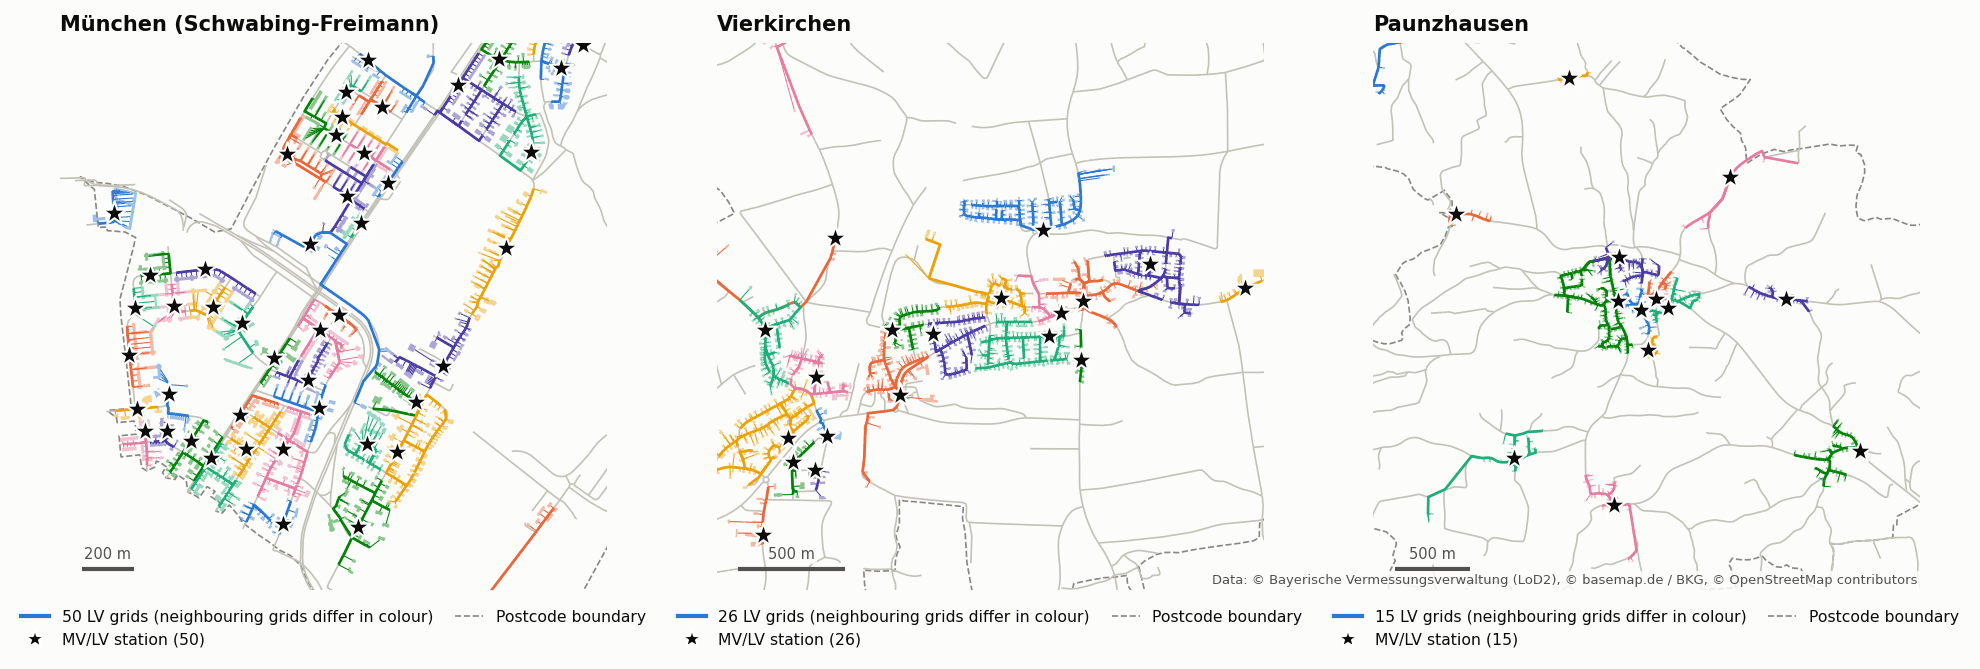

In [3]:
fig, axes = plt.subplots(1, len(areas), figsize=(16, 6))
for ax, plz in zip(axes, areas):
    name = EXAMPLE_AREAS.get(plz, {}).get("name", plz)
    last = plz == areas[-1]
    extent = lv_grid.core_bounds(data[plz].layers, aspect=1.0)
    lv_grid.plot_lv_overview(data[plz].layers, extent=extent, ax=ax, title=str(name), labels=False,
                             attribution=None if last else "")

## 2 Key figures

Grids per area, and what a typical grid looks like in each (median over the grids of the area).

In [4]:
rows = {}
for plz in areas:
    grids = data[plz].summary()
    postcode = data[plz].layers["postcode"].iloc[0]
    rows[EXAMPLE_AREAS.get(plz, {}).get("name", plz)] = {
        "settlement type": lv_grid.SETTLEMENT_NAMES[int(postcode["settlement_type"])],
        "households per building": round(postcode["avg_households_per_building"], 1),
        "house distance (m)": round(postcode["house_distance"]),
        "LV grids": len(grids),
        "buildings per grid": grids["buildings"].median(),
        "households per grid": grids["households"].median(),
        "station rating (kVA)": grids["transformer_rated_power"].median(),
        "feeder metres per building": round(1000 * (grids["feeder_km"] / grids["buildings"]).median()),
    }
pd.DataFrame(rows)

,München (Schwabing-Freimann),Vierkirchen,Paunzhausen
settlement type,urban,semi-urban,rural
households per building,7.1,1.6,1.4
house distance (m),29,36,44
LV grids,50,26,15
buildings per grid,23.5,42.5,30.0
households per grid,197.0,75.5,44.0
station rating (kVA),515.0,400.0,250.0
feeder metres per building,17,24,24


## 3 Stations and cables

The city needs larger stations for more households on fewer metres of cable; the village needs long feeders for
few houses.

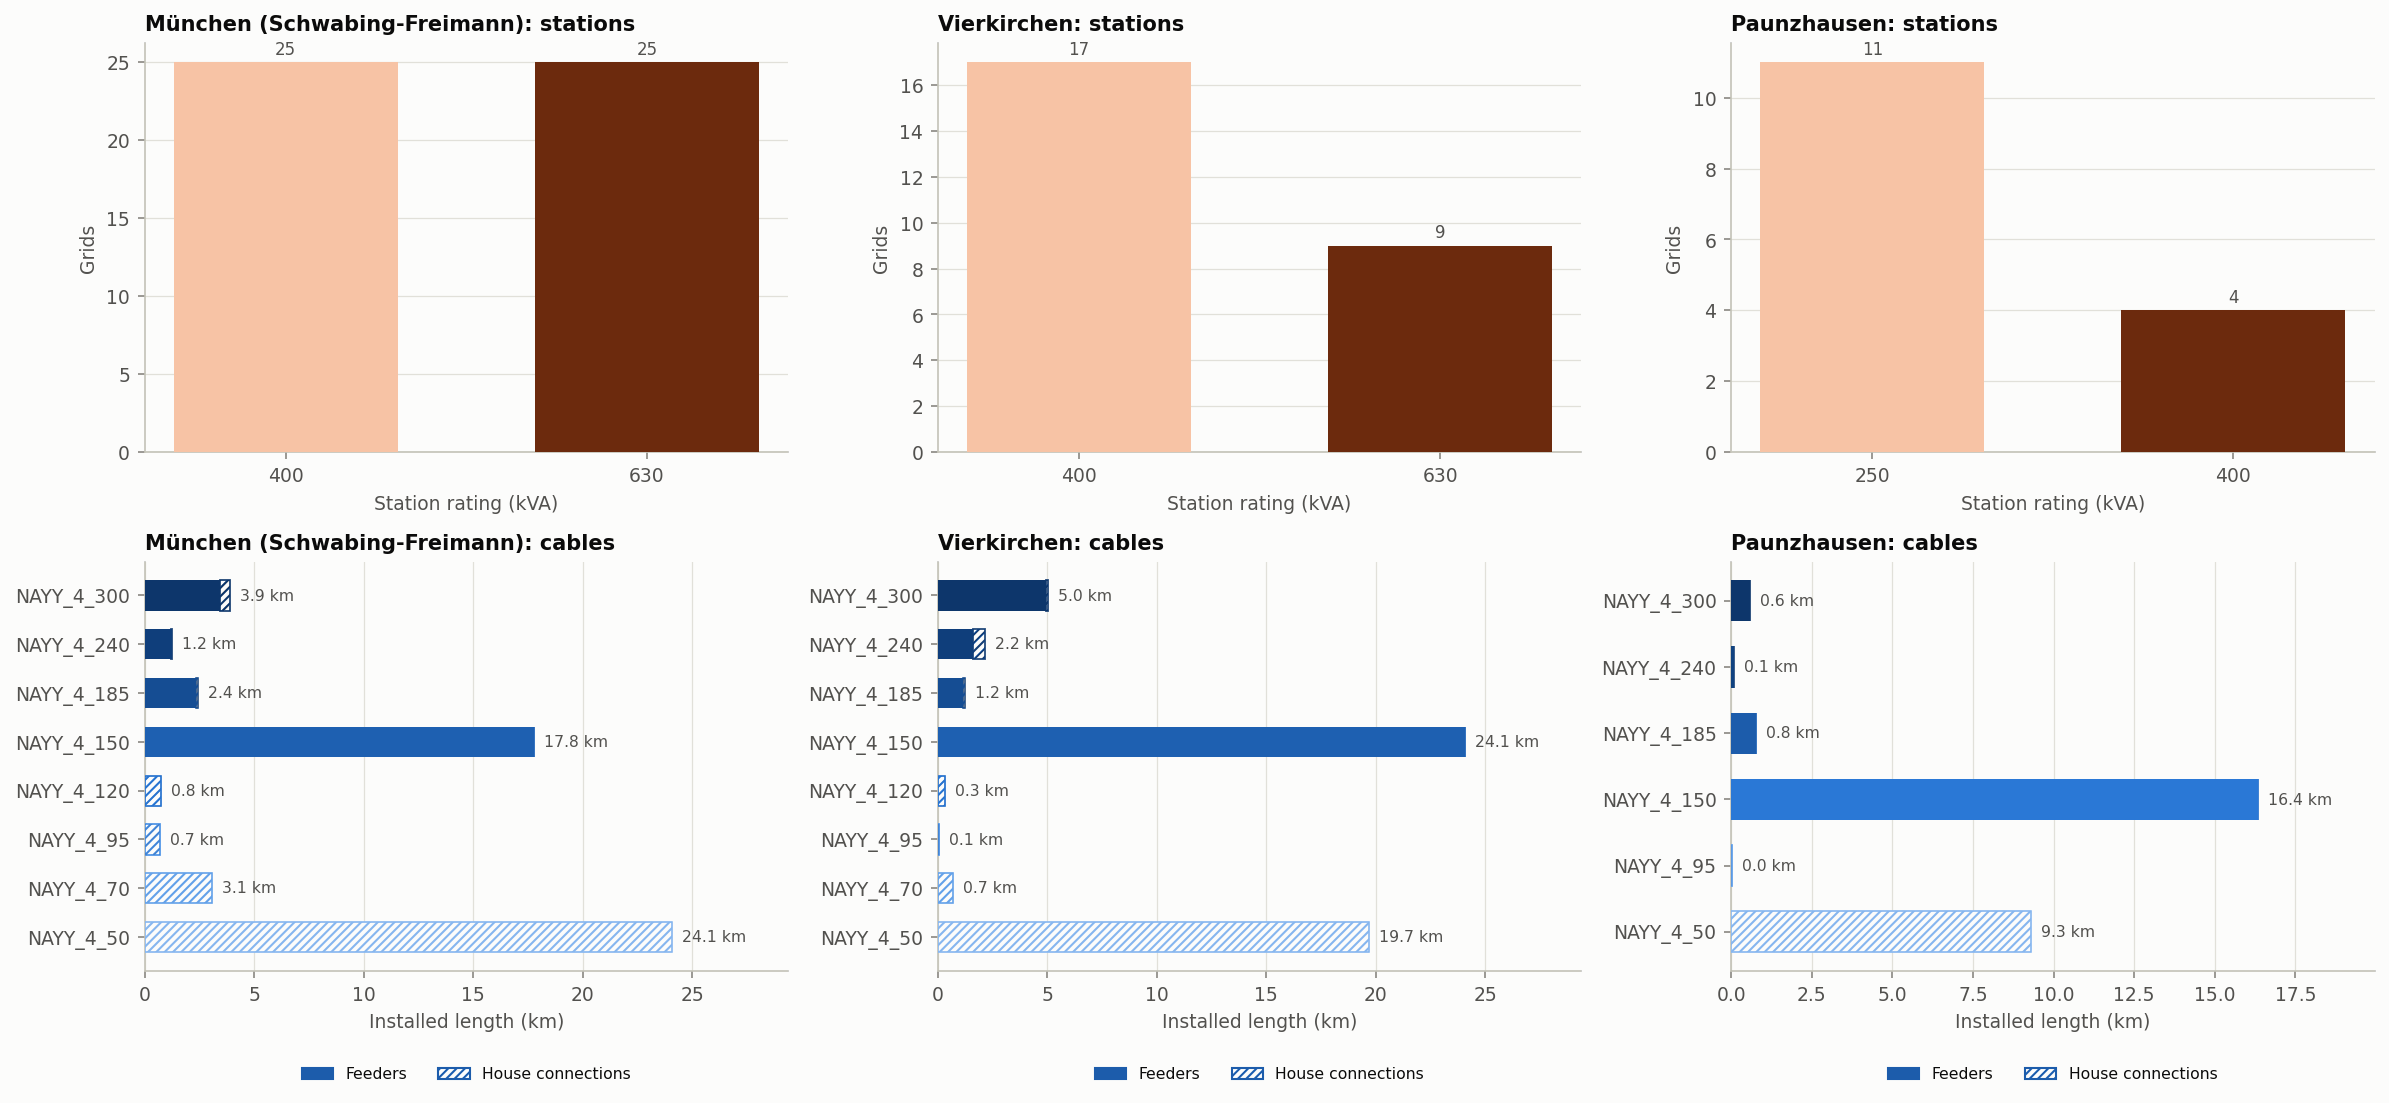

In [5]:
fig, axes = plt.subplots(2, len(areas), figsize=(16, 7.4))
for column, plz in enumerate(areas):
    name = EXAMPLE_AREAS.get(plz, {}).get("name", plz)
    lv_grid.plot_rating_counts(data[plz].grids, ax=axes[0, column], title=f"{name}: stations")
    lv_grid.plot_cable_inventory(data[plz].layers["lines"], ax=axes[1, column], title=f"{name}: cables")
fig.tight_layout()

## 4 All of Bavaria

The example areas are typical of their type. The distributions show how all 86,721 grids of the Bavaria run spread
by settlement type (in the example data: the key figures of all grids, rounded to three digits).

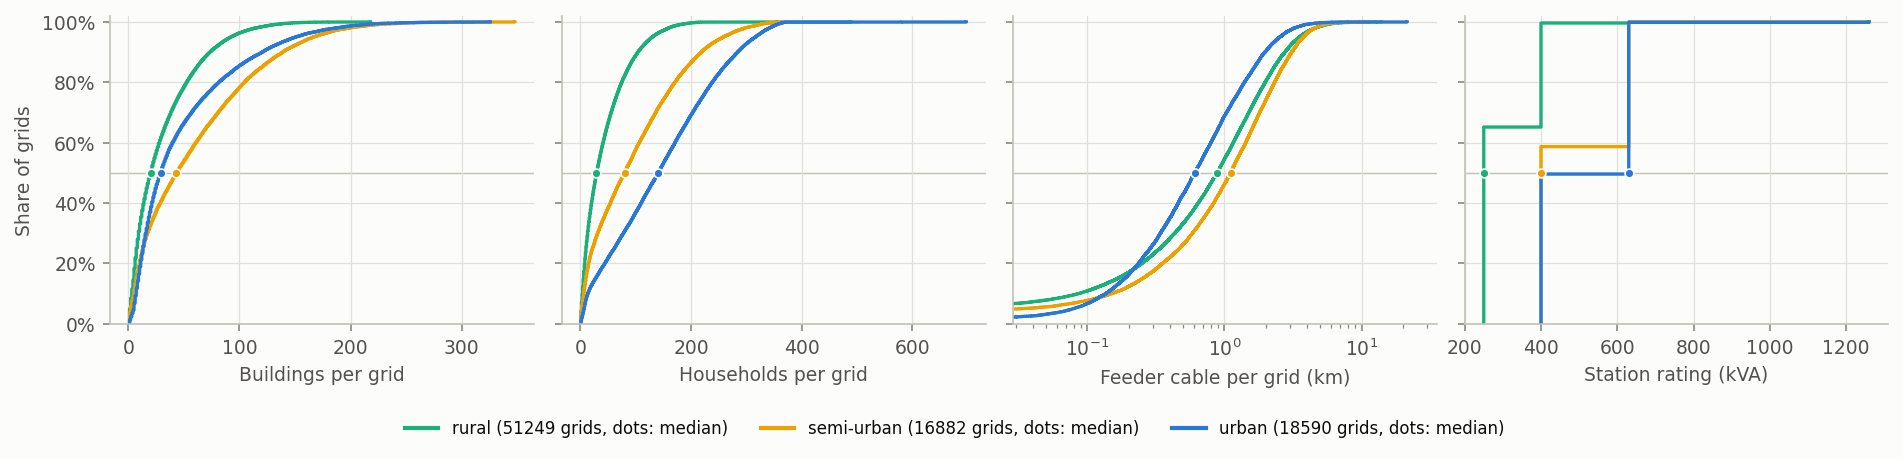

In [6]:
summary = data[areas[0]].region_summary()
fig = lv_grid.plot_grid_distributions(summary, by="settlement_type")

In [7]:
summary["feeder metres per building"] = 1000 * summary["feeder_km"] / summary["buildings"]
medians = summary.groupby("settlement_type")[["buildings", "households", "feeder_km", "feeder metres per building"]]
medians.median().round(1).rename(index=lv_grid.SETTLEMENT_NAMES)

,buildings,households,feeder_km,feeder metres per building
settlement_type,,,,
rural,20.0,29.0,0.9,29.5
semi-urban,43.0,80.0,1.1,21.7
urban,29.0,141.0,0.6,16.9


- Urban grids supply the most households with the least feeder cable per building. Rural grids supply the fewest
  households with the most cable per building. Semi-urban grids have the most buildings.
- The spread within each type is wide, so no single typical grid stands for a region. The classification notebooks
  (`classification/01`, `classification/02`) group the grids into types instead.